# Лабораторная работа: Классификация — ансамблевые методы (assembling / metode mixte)

**Цель:** на датасете недвижимости предсказать **ценовой класс** объекта (Budget / Mid / Premium) и сравнить три модели: `LogisticRegression` (базовая модель), `RandomForestClassifier` (бэггинг), `GradientBoostingClassifier` (бустинг) и `StackingClassifier` (стекинг).

**Файл данных:** `real_estate_regression_dataset.csv`.

> *Откуда классы.* В датасете цена — число (`SalePrice`). Для классификации мы делим объекты на три равные по размеру группы по цене: 33% самых дешёвых — **Budget**, средние — **Mid**, 33% самых дорогих — **Premium**. Сама цена в признаки **не попадает**, иначе задача станет тривиальной (утечка целевой переменной).
>
> *«Metode mixte» / assembling* — ансамблевые методы: бэггинг (Random Forest), бустинг (Gradient Boosting) и стекинг (StackingClassifier). LogisticRegression используется как базовая модель для сравнения результатов ансамблевых алгоритмов.

## Глава 1. Загрузка и первичный анализ данных
Подключаем библиотеки, загружаем файл, смотрим размер, типы, пропуски и дубликаты.


In [1]:
# Импорт библиотек
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # убирает ложные предупреждения macOS

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)
from sklearn.ensemble import StackingClassifier

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

In [2]:
# Загрузка данных
df = pd.read_csv("../data/real_estate_regression_dataset.csv")
print("Строк:", df.shape[0], "| Столбцов:", df.shape[1])
df.head()

Строк: 2840 | Столбцов: 28


,Id,Neighborhood,PropertyType,OverallQual,Condition,RenovationQuality,GrLivArea,LotArea,TotalBsmtSF,Rooms,Bedrooms,Bathrooms,Floor,TotalFloors,YearBuilt,YearRenovated,PropertyAge,GarageType,GarageCars,GarageArea,HeatingType,EnergyEfficiency,DistanceToCenter,HasPool,HasBalcony,CrimeRate,SchoolRating,SalePrice
0,994,GreenPark,Townhouse,9,Average,High,121,154.0,104.0,5,4,2,1,2,2016,2024.0,8,Detached,1,22.0,Electric,98.0,4.8,0,0,4.8,9.1,641900
1,279,Eastgate,House,9,Fair,Medium,90,1227.0,50.0,4,3,3,1,2,1982,2018.0,42,Attached,1,17.0,Gas,97.0,7.7,0,0,3.5,5.4,283500
2,820,OldTown,Apartment,4,Good,Low,104,0.0,0.0,3,2,1,1,5,1992,2024.0,32,NoGarage,0,0.0,Gas,97.0,2.5,0,0,4.6,5.9,365300
3,2700,Eastgate,Apartment,5,Good,Low,80,0.0,0.0,4,1,2,6,10,2012,2024.0,12,Underground,1,30.0,District,100.0,8.4,0,1,5.2,9.5,341200
4,1205,Downtown,House,9,Excellent,Medium,156,583.0,135.0,7,5,3,1,1,2018,2024.0,6,Detached,2,49.0,Electric,100.0,0.3,1,0,7.0,6.7,1238000


In [3]:
# Названия признаков и их типы
df.dtypes

Id                     int64
Neighborhood          object
PropertyType          object
OverallQual            int64
Condition             object
RenovationQuality     object
GrLivArea              int64
LotArea              float64
TotalBsmtSF          float64
Rooms                  int64
Bedrooms               int64
Bathrooms              int64
Floor                  int64
TotalFloors            int64
YearBuilt              int64
YearRenovated        float64
PropertyAge            int64
GarageType            object
GarageCars             int64
GarageArea           float64
HeatingType           object
EnergyEfficiency     float64
DistanceToCenter     float64
HasPool                int64
HasBalcony             int64
CrimeRate            float64
SchoolRating         float64
SalePrice              int64
dtype: object

In [4]:
# Пропуски (только где они есть) и полные дубликаты
missing = df.isna().sum()
print("Пропуски по столбцам:")
print(missing[missing > 0].sort_values(ascending=False))
print("\nПолных дубликатов:", df.duplicated().sum())

Пропуски по столбцам:
EnergyEfficiency     310
YearRenovated        251
TotalBsmtSF          249
RenovationQuality    245
GarageType           182
SchoolRating         179
HeatingType          162
CrimeRate            150
Condition            145
LotArea              145
GarageArea           122
dtype: int64

Полных дубликатов: 40


## Глава 2. Очистка и подготовка данных
1. Удаляем полные дубликаты.
2. **Выбросы не удаляем:** дорогие и очень большие объекты возможны в реальности (они попадут в класс Premium).
3. Пропуски заполним **внутри Pipeline** (глава 4).

> **Утечка данных.** Если заполнять пропуски по всей таблице до разделения на train/test, статистики «подсмотрят» тест. `Pipeline` + `ColumnTransformer` считают всё только по обучающей выборке.

In [5]:
# Удаляем полные дубликаты
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Удалено дубликатов: {before - len(df)}. Осталось строк: {len(df)}")

# Проверяем пропуски после удаления дубликатов (заполнять будем позже, в Pipeline)
print("\nВсего пропусков:", int(df.isna().sum().sum()))
print("Столбцов с пропусками:", int((df.isna().sum() > 0).sum()))

# Сохраняем очищенный от дубликатов набор (пропуски и выбросы пока оставляем)
df.to_csv("real_estate_regression_clean.csv", index=False)

Удалено дубликатов: 40. Осталось строк: 2800

Всего пропусков: 2111
Столбцов с пропусками: 11


In [6]:
# Создаём целевой признак: ценовой класс (три равные по размеру группы по цене)
df["PriceClass"] = pd.qcut(df["SalePrice"], q=3, labels=["Budget", "Mid", "Premium"])

# Границы классов и число объектов в каждом
print(df.groupby("PriceClass", observed=True)["SalePrice"].agg(["min", "max", "count"]))

               min      max  count
PriceClass                        
Budget       82500   364800    933
Mid         365300   523200    934
Premium     523700  2951700    933


**Как сформированы классы.** Граница между классами — это квантили цены (33-й и 67-й процентили): `pd.qcut(..., q=3)` делит объекты на три группы равного размера. Плюсы такого способа: классы сбалансированы, а выбросы (очень дорогие объекты) не растягивают границы и просто попадают в класс Premium. Количество объектов в классах показано в таблице выше.

## Глава 3. Краткий анализ данных
Смотрим баланс классов и то, как классы различаются по важным признакам.

In [7]:
# Основные статистики числовых признаков
df.drop(columns=["Id"]).describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
OverallQual,2800.0,6.1,1.6,1.0,5.0,6.0,7.0,10.0
GrLivArea,2800.0,129.1,58.9,29.0,85.0,120.0,159.0,538.0
LotArea,2659.0,339.9,558.4,0.0,0.0,224.0,466.0,11197.0
TotalBsmtSF,2554.0,55.6,56.5,0.0,0.0,54.0,92.0,449.0
Rooms,2800.0,5.4,1.8,2.0,4.0,5.0,6.0,11.0
Bedrooms,2800.0,3.4,1.6,1.0,2.0,3.0,4.0,12.0
Bathrooms,2800.0,2.2,1.0,1.0,1.0,2.0,3.0,7.0
Floor,2800.0,2.6,3.3,1.0,1.0,1.0,2.0,19.0
TotalFloors,2800.0,4.7,5.1,1.0,2.0,2.0,6.0,19.0
YearBuilt,2800.0,1988.8,21.0,1890.0,1975.0,1989.0,2004.0,2024.0


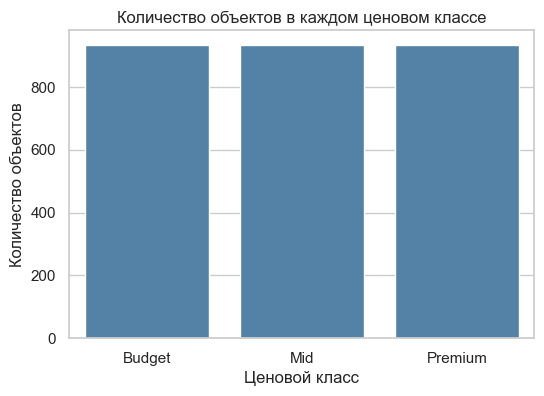

In [8]:
# Распределение классов
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="PriceClass", order=["Budget", "Mid", "Premium"], color="steelblue")
plt.title("Количество объектов в каждом ценовом классе")
plt.xlabel("Ценовой класс")
plt.ylabel("Количество объектов")
plt.show()

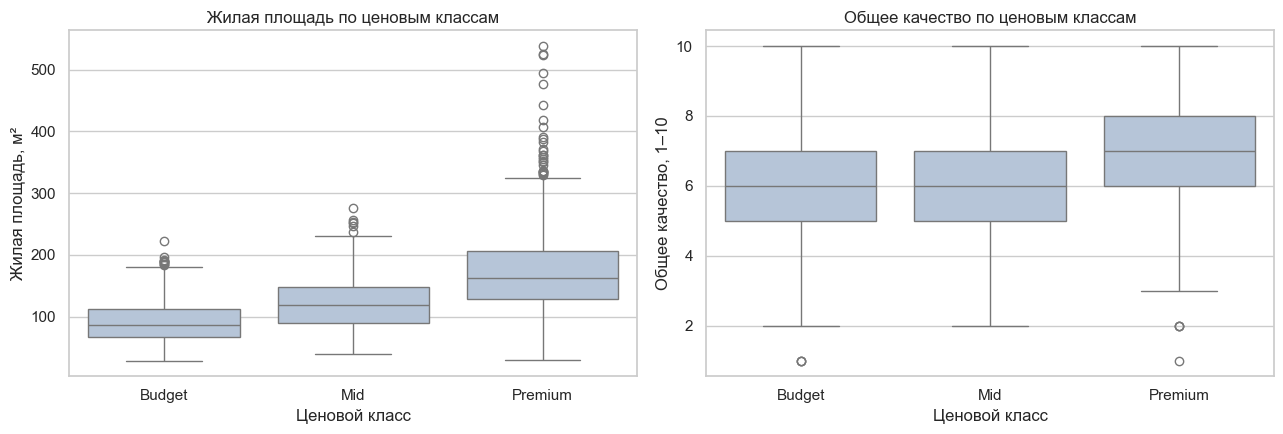

In [9]:
# Как классы отличаются по площади и качеству
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = ["Budget", "Mid", "Premium"]

sns.boxplot(data=df, x="PriceClass", y="GrLivArea", order=order, ax=axes[0], color="lightsteelblue")
axes[0].set_title("Жилая площадь по ценовым классам")
axes[0].set_xlabel("Ценовой класс")
axes[0].set_ylabel("Жилая площадь, м²")

sns.boxplot(data=df, x="PriceClass", y="OverallQual", order=order, ax=axes[1], color="lightsteelblue")
axes[1].set_title("Общее качество по ценовым классам")
axes[1].set_xlabel("Ценовой класс")
axes[1].set_ylabel("Общее качество, 1–10")

plt.tight_layout()
plt.show()

## Глава 4. Подготовка к классификации
- `y` — класс `PriceClass`;
- `X` — все остальные признаки, **кроме `Id` и `SalePrice`** (цену убираем, иначе модель «увидит ответ»);
- разделение 80/20 с `random_state=42` и `stratify=y`, чтобы доли классов в train и test были одинаковыми;
- числа: медиана + масштабирование; категории: самое частое значение + One-Hot.

In [10]:
# Целевой признак и признаки
y = df["PriceClass"].astype(str)
X = df.drop(columns=["PriceClass", "SalePrice", "Id"])

# Разделение 80/20 с сохранением пропорций классов
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Обучающая выборка:", X_train.shape, "| Тестовая:", X_test.shape)
print(y_test.value_counts())

Обучающая выборка: (2240, 26) | Тестовая: (560, 26)
PriceClass
Budget     187
Mid        187
Premium    186
Name: count, dtype: int64


In [11]:
# Списки числовых и категориальных признаков
num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
print("Числовые:", len(num_cols), "| Категориальные:", cat_cols)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),   # редкие категории в тесте не вызовут ошибку
])
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

Числовые: 20 | Категориальные: ['Neighborhood', 'PropertyType', 'Condition', 'RenovationQuality', 'GarageType', 'HeatingType']


## Глава 5. Построение классификационных моделей
Каждая модель — `Pipeline` из предобработки и классификатора. Обучаем только на обучающей выборке.

- **LogisticRegression** — базовая линейная модель, оценивает вероятность каждого класса.
- **RandomForestClassifier** — много деревьев, класс выбирается голосованием (бэггинг).
- **GradientBoostingClassifier** — деревья строятся последовательно, исправляя ошибки предыдущих (бустинг).

In [12]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "Stacking Classifier": StackingClassifier(
        estimators=[
            ("rf", RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
            ("gb", GradientBoostingClassifier(random_state=42))
        ],
        final_estimator=LogisticRegression(max_iter=2000),
        cv=5,
        n_jobs=-1
    ),
}

pipelines = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    pipe.fit(X_train, y_train)          # обучение только на train
    pipelines[name] = pipe
    print("Обучена модель:", name)

Обучена модель: Logistic Regression
Обучена модель: Random Forest
Обучена модель: Gradient Boosting
Обучена модель: Stacking Classifier


## Глава 6. Оценка качества моделей
На **одной и той же тестовой выборке** считаем:
- **Accuracy** — доля верно классифицированных объектов;
- **Precision** — из объектов, отнесённых к классу, какая доля действительно к нему относится;
- **Recall** — какую долю объектов класса модель нашла;
- **F1** — среднее Precision и Recall.

Precision, Recall и F1 усредняем по трём классам вариантом `weighted`: вклад каждого класса пропорционален числу его объектов (здесь классы почти равны, поэтому разница с `macro` минимальна).

In [13]:
preds = {}
rows = []
for name, pipe in pipelines.items():
    p = pipe.predict(X_test)
    preds[name] = p
    rows.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, p),
        "Precision": precision_score(y_test, p, average="weighted"),
        "Recall": recall_score(y_test, p, average="weighted"),
        "F1": f1_score(y_test, p, average="weighted"),
    })

results = pd.DataFrame(rows).set_index("Модель").round(3)
results.sort_values("F1", ascending=False)

,Accuracy,Precision,Recall,F1
Модель,,,,
Logistic Regression,0.877,0.879,0.877,0.878
Stacking Classifier,0.816,0.822,0.816,0.818
Gradient Boosting,0.805,0.814,0.805,0.808
Random Forest,0.770,0.775,0.770,0.772


In [14]:
    # Лучшая модель по каждой метрике
    for metric in results.columns:
        print(f"Лучшая по {metric}: {results[metric].idxmax()} ({results[metric].max():.3f})")

Лучшая по Accuracy: Logistic Regression (0.877)
Лучшая по Precision: Logistic Regression (0.879)
Лучшая по Recall: Logistic Regression (0.877)
Лучшая по F1: Logistic Regression (0.878)


In [15]:
# Подробный отчёт по классам для лучшей модели (по F1)
best = results["F1"].idxmax()
print("Модель:", best)
print(classification_report(y_test, preds[best], labels=["Budget", "Mid", "Premium"]))

Модель: Logistic Regression
              precision    recall  f1-score   support

      Budget       0.92      0.90      0.91       187
         Mid       0.80      0.85      0.82       187
     Premium       0.92      0.88      0.90       186

    accuracy                           0.88       560
   macro avg       0.88      0.88      0.88       560
weighted avg       0.88      0.88      0.88       560



## Глава 7. Графики классификации
Матрицы ошибок для каждой модели и сравнение метрик.

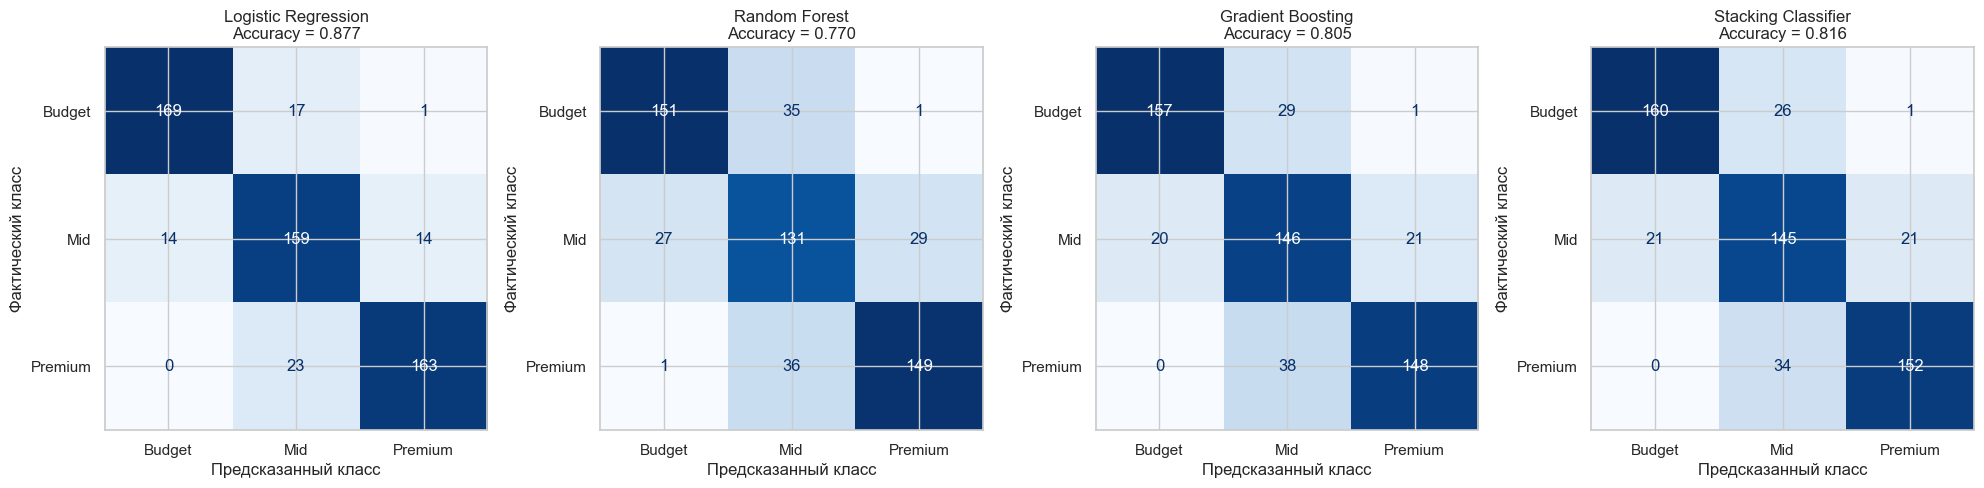

In [16]:
# Матрицы ошибок (строки — факт, столбцы — прогноз)
labels = ["Budget", "Mid", "Premium"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8))
for ax, (name, p) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, p, labels=labels)
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, p):.3f}")
    ax.set_xlabel("Предсказанный класс")
    ax.set_ylabel("Фактический класс")
plt.tight_layout()
plt.show()

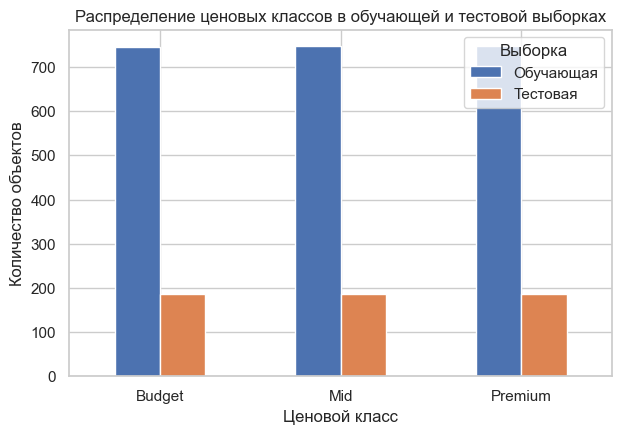

In [17]:
# Распределение классов в обучающей и тестовой выборках
dist = pd.DataFrame({"Обучающая": y_train.value_counts(), "Тестовая": y_test.value_counts()}).loc[labels]
dist.plot(kind="bar", figsize=(7, 4.5), rot=0)
plt.title("Распределение ценовых классов в обучающей и тестовой выборках")
plt.xlabel("Ценовой класс")
plt.ylabel("Количество объектов")
plt.legend(title="Выборка")
plt.show()

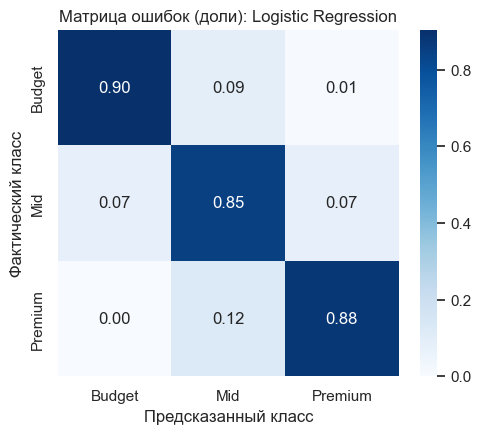

In [18]:
# Матрица ошибок лучшей модели (по F1), в процентах по строкам
best = results["F1"].idxmax()
cm_norm = confusion_matrix(y_test, preds[best], labels=labels, normalize="true")
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.title(f"Матрица ошибок (доли): {best}")
plt.xlabel("Предсказанный класс")
plt.ylabel("Фактический класс")
plt.show()

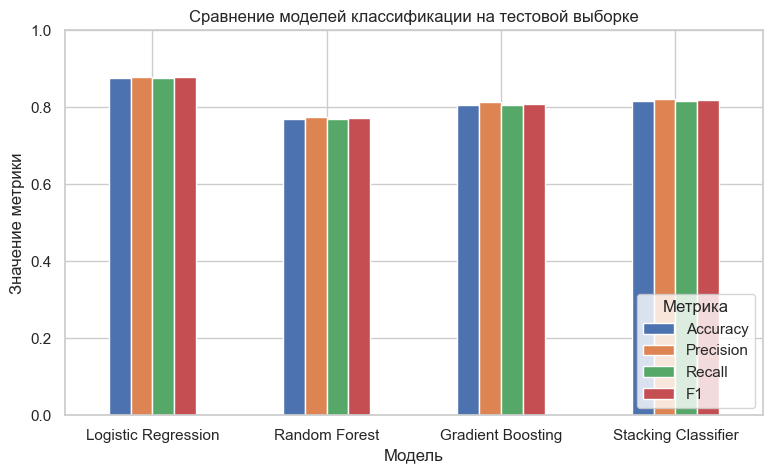

In [19]:
# Сравнение метрик моделей
results.plot(kind="bar", figsize=(9, 5), rot=0)
plt.title("Сравнение моделей классификации на тестовой выборке")
plt.xlabel("Модель")
plt.ylabel("Значение метрики")
plt.ylim(0, 1)
plt.legend(title="Метрика", loc="lower right")
plt.show()

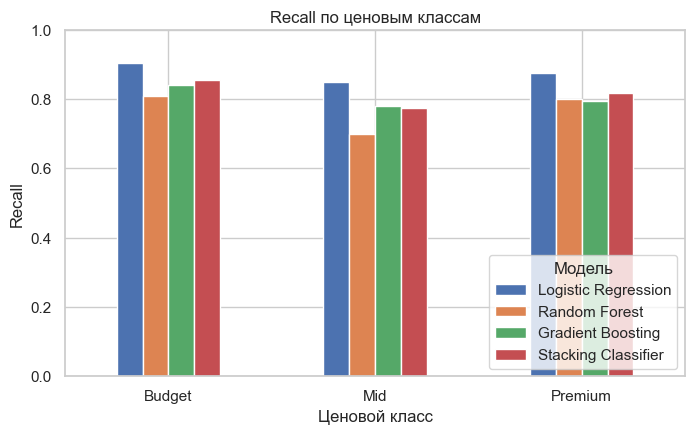

In [20]:
# Доля верных ответов по каждому классу (Recall) для всех моделей
rec = {name: recall_score(y_test, p, average=None, labels=labels) for name, p in preds.items()}
rec = pd.DataFrame(rec, index=labels)
rec.plot(kind="bar", figsize=(8, 4.5), rot=0)
plt.title("Recall по ценовым классам")
plt.xlabel("Ценовой класс")
plt.ylabel("Recall")
plt.ylim(0, 1)
plt.legend(title="Модель", loc="lower right")
plt.show()

## Глава 8. Заключение
Текст ниже формируется автоматически по реальным результатам, полученным выше.

In [21]:
best = results["F1"].idxmax()
b = results.loc[best]
worst = results["F1"].idxmin()

print("Выполнено: загрузка и очистка данных (удалены дубликаты), создание трёх ценовых классов, "
      "краткий анализ, разделение 80/20 со стратификацией и обучение четырёх моделей через Pipeline.")
print(f"Всего объектов после очистки: {len(df)}; тестовая выборка: {len(X_test)}.")
print()
print(f"Лучший результат по F1 показала модель «{best}»: Accuracy = {b['Accuracy']:.3f}, "
      f"Precision = {b['Precision']:.3f}, Recall = {b['Recall']:.3f}, F1 = {b['F1']:.3f}.")
print(f"Худший результат по F1 у модели «{worst}» (F1 = {results.loc[worst, 'F1']:.3f}).")
print(f"Accuracy = {b['Accuracy']:.3f} означает, что лучшая модель верно определяет ценовой класс "
      f"примерно у {b['Accuracy'] * 100:.1f}% объектов.")

# Какие классы определяются лучше и хуже (Recall лучшей модели по классам)
rec_best = pd.Series(recall_score(y_test, preds[best], average=None, labels=labels), index=labels)
print(f"Лучше всего определяется класс {rec_best.idxmax()} (Recall = {rec_best.max():.3f}), "
      f"хуже всего — {rec_best.idxmin()} (Recall = {rec_best.min():.3f}).")

# Где чаще всего ошибается лучшая модель
cm = confusion_matrix(y_test, preds[best], labels=labels)
np.fill_diagonal(cm, 0)
i, j = np.unravel_index(cm.argmax(), cm.shape)
print(f"Чаще всего лучшая модель путает: фактический класс {labels[i]} -> предсказан {labels[j]} ({cm[i, j]} случаев).")

Выполнено: загрузка и очистка данных (удалены дубликаты), создание трёх ценовых классов, краткий анализ, разделение 80/20 со стратификацией и обучение четырёх моделей через Pipeline.
Всего объектов после очистки: 2800; тестовая выборка: 560.

Лучший результат по F1 показала модель «Logistic Regression»: Accuracy = 0.877, Precision = 0.879, Recall = 0.877, F1 = 0.878.
Худший результат по F1 у модели «Random Forest» (F1 = 0.772).
Accuracy = 0.877 означает, что лучшая модель верно определяет ценовой класс примерно у 87.7% объектов.
Лучше всего определяется класс Budget (Recall = 0.904), хуже всего — Mid (Recall = 0.850).
Чаще всего лучшая модель путает: фактический класс Premium -> предсказан Mid (23 случаев).


**Ограничения эксперимента:**
- данные синтетические, поэтому выводы нельзя напрямую переносить на реальный рынок недвижимости;
- классы получены делением непрерывной цены по квантилям: объекты у границ классов почти неотличимы, поэтому часть ошибок неизбежна;
- одно разбиение train/test с `random_state=42`: на другом разбиении цифры немного изменятся (надёжнее было бы использовать кросс-валидацию);
- гиперпараметры ансамблей не подбирались, использованы значения по умолчанию.

- Лучший результат по F1 показала Logistic Regression. Это может объясняться тем, что в синтетических данных связь признаков с ценой достаточно хорошо описывается линейными зависимостями, а границы между ценовыми классами относительно простые. Это возможное объяснение, а не доказанная причина превосходства модели.
- Ошибки чаще возникают между **соседними** классами (Budget–Mid, Mid–Premium), потому что объекты у границы цены очень похожи.
- Модели можно улучшить подбором гиперпараметров (GridSearchCV) и настройкой ансамблевых методов. В эксперимент уже включён StackingClassifier, однако он не показал результат лучше Logistic Regression.